In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv("Car Price Prediction.csv")
print("Shape:", df.shape)
print(df[["enginesize", "horsepower", "citympg", "curbweight", "price"]].describe().T, "\n")

Shape: (205, 26)
            count          mean          std     min     25%      50%  \
enginesize  205.0    126.907317    41.642693    61.0    97.0    120.0   
horsepower  205.0    104.117073    39.544167    48.0    70.0     95.0   
citympg     205.0     25.219512     6.542142    13.0    19.0     24.0   
curbweight  205.0   2555.565854   520.680204  1488.0  2145.0   2414.0   
price       205.0  13276.710571  7988.852332  5118.0  7788.0  10295.0   

                75%      max  
enginesize    141.0    326.0  
horsepower    116.0    288.0  
citympg        30.0     49.0  
curbweight   2935.0   4066.0  
price       16503.0  45400.0   



In [3]:
features = ["enginesize", "horsepower", "citympg", "curbweight"]
X = df[features].values
y = df["price"].values

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

results = []
def evaluate(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    results.append({"Model": name, "R2": round(r2, 4),
                     "MAE ($)": round(mae, 1), "RMSE ($)": round(rmse, 1)})

In [4]:
lin_model = make_pipeline(StandardScaler(), LinearRegression())
lin_model.fit(X_train, y_train)
y_pred_lin = lin_model.predict(X_test)
evaluate("Linear Regression", y_test, y_pred_lin)

In [5]:
poly_models = {}
for deg in [2, 3, 4]:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=deg, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    evaluate(f"Polynomial (deg={deg})", y_test, y_pred)
    poly_models[deg] = model

results_df = pd.DataFrame(results)
print("Performance comparison:\n", results_df.to_string(index=False), "\n")

Performance comparison:
              Model      R2  MAE ($)  RMSE ($)
 Linear Regression  0.8157   2768.6    3814.8
Polynomial (deg=2)  0.8132   2529.6    3840.0
Polynomial (deg=3)  0.8010   2596.8    3963.4
Polynomial (deg=4) -0.4521   4664.6   10706.9 



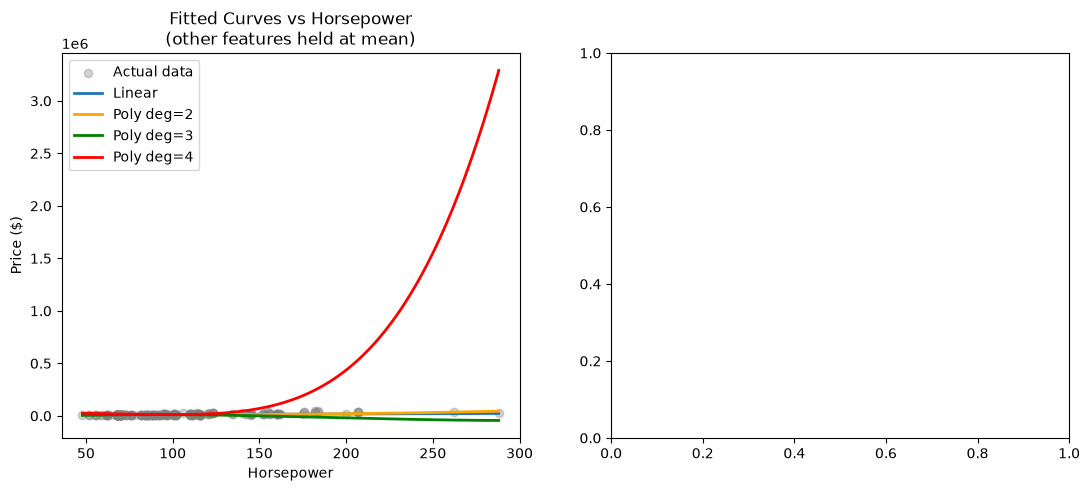

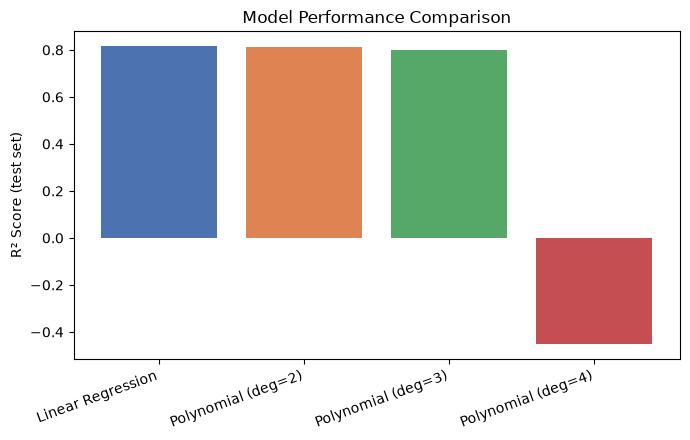

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

mean_eng   = df["enginesize"].mean()
mean_hp    = df["horsepower"].mean()
mean_mpg   = df["citympg"].mean()
mean_wt    = df["curbweight"].mean()

# ---- (a) Horsepower vs Price ----
hp_range = np.linspace(df["horsepower"].min(), df["horsepower"].max(), 200)
axes[0].scatter(df["horsepower"], df["price"], alpha=0.35, color="gray", label="Actual data")
X_curve = np.column_stack([
    np.full_like(hp_range, mean_eng),
    hp_range,
    np.full_like(hp_range, mean_mpg),
    np.full_like(hp_range, mean_wt)
])
axes[0].plot(hp_range, lin_model.predict(X_curve), label="Linear", linewidth=2)
for deg, color in zip([2, 3, 4], ["orange", "green", "red"]):
    axes[0].plot(hp_range, poly_models[deg].predict(X_curve),
                 label=f"Poly deg={deg}", linewidth=2, color=color)
axes[0].set_xlabel("Horsepower")
axes[0].set_ylabel("Price ($)")
axes[0].set_title("Fitted Curves vs Horsepower\n(other features held at mean)")
axes[0].legend()
plt.show()

# ---- (b) Engine Size vs Price ----
eng_range = np.linspace(df["enginesize"].min(), df["enginesize"].max(), 200)
axes[1].scatter(df["enginesize"], df["price"], alpha=0.35, color="gray", label="Actual data")
X_curve2 = np.column_stack([
    eng_range,
    np.full_like(eng_range, mean_hp),
    np.full_like(eng_range, mean_mpg),
    np.full_like(eng_range, mean_wt)
])
axes[1].plot(eng_range, lin_model.predict(X_curve2), label="Linear", linewidth=2)
for deg, color in zip([2, 3, 4], ["orange", "green", "red"]):
    axes[1].plot(eng_range, poly_models[deg].predict(X_curve2),
                 label=f"Poly deg={deg}", linewidth=2, color=color)
axes[1].set_xlabel("Engine Size")
axes[1].set_ylabel("Price ($)")
axes[1].set_title("Fitted Curves vs Engine Size\n(other features held at mean)")
axes[1].legend()
plt.show()

# ---- (c) R2 comparison bar chart ----
plt.figure(figsize=(7, 4.5))
plt.bar(results_df["Model"], results_df["R2"], color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
plt.ylabel("R² Score (test set)")
plt.title("Model Performance Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
